# 02 End-to-end chemical maps: a U-Net ensemble against pixel-wise PLS

Rebuilt from the course notebook `2026/end2end_unet_chemical_maps.ipynb` (https://github.com/LizaGenke/Chemometric-approaches-to-hyperspectral-processing, commit
`0d2c33e`). The course loads the five-member U-Net ensemble of Engstrom et al. (2025,
Hugging Face `Sm00thix/unet_chemical_map`, weights CC BY-NC 4.0, code LGPL-3.0), predicts fat maps
of pork belly slices, and compares them with a classical route: a PLS model fitted on mean spectra
(SNV, Savitzky-Golay second derivative) applied pixel by pixel. Here the study code is vendored
under `cuvis_ai_wur_course/upstream/unet_chemical_map`, the ensemble is one node, and the
classical route is a chain of pretreatment nodes ending in `PLSRegression`.

In [1]:
# Colab bootstrap: installs cuvis-ai when this notebook runs on Colab, a no-op locally. The course
# plugin lives in a private repository until the course authors confirm the licence, so for now the
# notebook runs from a local checkout of this repository (`uv sync --all-extras`).
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q cuvis-ai

In [2]:
# Provision the plugins this notebook needs. Their pins live in the plugin manifests packaged with
# cuvis-ai (cuvis_ai/configs/plugins) and in this repository's own manifest (plugins/): `provision`
# reads them off a pipeline that lists the same plugins, adds each manifest's extras and the data
# module's, and installs only what is missing. After a fresh install, restart the kernel
# (Kernel > Restart Kernel) and rerun from the top. This repository also pins the sam3 and
# ultralytics plugins as its `plugins` extra, so `uv sync --all-extras` has installed them already.
from importlib.resources import files
from pathlib import Path

from cuvis_ai_core.utils.provision import provision_environment, resolve_install_specs

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
CONFIGS = files("cuvis_ai") / "configs"
PLUGINS_DIRS = [REPO / "plugins", Path(str(CONFIGS / "plugins"))]
PROVISION = [  # (pipeline of this repository that lists the plugin(s), data module whose extras to add)
    ("02_unet_chemical_maps/unet_ensemble_maps.yaml", 'wur_course_npz'),
]
for pipeline_yaml, data_module in PROVISION:
    pipeline_path = REPO / "pipelines" / pipeline_yaml
    if IN_COLAB:  # no uv project on Colab: pip the resolved specs straight into this kernel
        specs = resolve_install_specs(pipeline_path, PLUGINS_DIRS, data_module)
        provision_environment(specs, notebook=True, apply=True)
    else:  # the same command you would run in a terminal from the repository root
        data_arg = f"--data-module {data_module}" if data_module else ""
        plugin_args = " ".join(f'--plugins-dir "{d}"' for d in PLUGINS_DIRS)
        !uv run --directory "{REPO}" provision --pipeline-path "{pipeline_path}" {plugin_args} {data_arg} --apply

2026-11-04 22:20:45.928 | DEBUG    | cuvis_ai_core.orchestrator.runtime_project:resolve_plugin_sources:224 - Resolved plugin 'cuvis_ai_builtin' tag v0.21.0 → 8c24a350 from https://github.com/cubert-hyperspectral/cuvis-ai.git
2026-11-04 22:20:46.032 | INFO     | cuvis_ai_core.utils.provision:provision_environment:212 - All plugins already provisioned; nothing to install.


In [3]:
import numpy as np
import pandas as pd
import torch
from loguru import logger

logger.remove()
logger.add(sys.stderr, level="INFO")

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DATA = REPO / "data" / "course"
# The stand-in written by tools/make_synthetic_course_data.py has the course's shapes and random
# content; with it the reproduction table reports our numbers without judging them.
SYNTHETIC = (REPO / "data" / "synthetic_course").exists()
sys.path.insert(0, str(REPO / "notebooks"))
import utils  # noqa: E402  (plotting and table helpers only)

print(f"device {DEVICE}, {'synthetic stand-in' if SYNTHETIC else 'course data'} under {DATA}")

device cuda, course data under D:\code-repos\cuvis-ai-wur-course-2026\wt-6957-standardize\data\course


## Data

The course data (the Drive folder of the WUR course) is not a `PublicDatasets` entry: it is shared
for the course, and its licence for a public repository is pending. This notebook therefore deviates
from the standard provisioning block: `prepare-course-data` converts the Drive folder into the npz
frames read here (`README.md` lists the commands), and `tools/make_synthetic_course_data.py` writes a
random stand-in with the course's shapes so every cell runs before the data arrives.

In [4]:
for subset in ('mean_spectra_03', 'image_slices'):
    if not (DATA / subset / "universe.csv").exists():
        raise FileNotFoundError(
            f"{DATA / subset} is missing: run prepare-course-data on the course folder, or "
            "`uv run python tools/make_synthetic_course_data.py` for the stand-in"
        )
pd.read_csv(DATA / 'mean_spectra_03' / "universe.csv").head()

,source,index,materialized_path
0,mean_spectra_03,0,frames/00000.npz
1,mean_spectra_03,1,frames/00001.npz
2,mean_spectra_03,2,frames/00002.npz
3,mean_spectra_03,3,frames/00003.npz
4,mean_spectra_03,4,frames/00004.npz


In [5]:
# The plugin manifests: this repository's course plugin, plus the packaged manifests of the plugins
# the pipelines list. The nodes below are constructed by import, so the registry is what a
# pipeline YAML or the restore-pipeline CLI resolves them through.
from cuvis_ai_core.utils.node_registry import NodeRegistry

registry = NodeRegistry()
registry.register_plugin(str(REPO / "plugins" / "cuvis_ai_wur_course.yaml"))

registry.list_plugins()

2026-11-04 22:20:58.806 | INFO     | cuvis_ai_core.utils.node_registry:register_plugins_installed:573 - Loaded preinstalled plugin 'cuvis_ai_wur_course' with 22 nodes


2026-11-04 22:20:58.807 | INFO     | cuvis_ai_core.utils.node_registry:register_plugin:408 - Registered plugin 'cuvis_ai_wur_course' from D:\code-repos\cuvis-ai-wur-course-2026\wt-6957-standardize\plugins\cuvis_ai_wur_course.yaml


['cuvis_ai_wur_course']

## 1. The classical route: PLS on mean spectra

The course bins the 124-band mean spectra pairwise to 62 bands while loading them, applies SNV
and a Savitzky-Golay second derivative (window 7, order 2, scipy's `interp` edge handling), and
fits PLS with the component count chosen by leaving each of the five CV splits out in turn and
summing the squared hold-out errors (`A_MAX` 20). The frames come from
`prepare-course-data mean-spectra-03` (124 bands, `fold` = the course split); the binning is a
node, so the chain reads like the course.

In [6]:
from cuvis_ai.node.pretreatments.standardize import Standardize
from cuvis_ai_core.data.splits_io import load_splits
from cuvis_ai_core.pipeline.pipeline import CuvisPipeline
from cuvis_ai_core.training import StatisticalTrainer
from cuvis_ai_wur_course.data.course_npz import CourseNpzDataModule
from cuvis_ai_wur_course.node.fusion import SpatialMean
from cuvis_ai_wur_course.node.metrics import RegressionMetrics
from cuvis_ai_wur_course.node.pretreatment import SavitzkyGolayInterp, SpectralBinning
from cuvis_ai_wur_course.node.regression import PLSRegression
from cuvis_ai_wur_course.node.source import CourseFrame

BANDS, BINNED, MAX_COMPONENTS = 124, 62, 20

spectra_frame = CourseFrame(name="frame")
binning = SpectralBinning(name="binning", input_channels=BANDS, bin_size=2)
snv = Standardize(name="snv", axis="spectrum", ddof=0)
sg = SavitzkyGolayInterp(name="sg", num_channels=BINNED, window_length=7, polyorder=2, deriv=2)
pls = PLSRegression(name="pls", input_channels=BINNED, max_components=MAX_COMPONENTS, holdout_folds="each", refit_on_holdout=True)
mean_pls = SpatialMean(name="mean_pls")
metrics_pls = RegressionMetrics(name="metrics_pls")

fit_pipeline = CuvisPipeline("pls_mean_spectra_fit")
fit_pipeline.connect(
    (spectra_frame.outputs.cube, binning.inputs.cube),
    (spectra_frame.outputs.wavelengths, binning.inputs.wavelengths),
    (binning.outputs.cube, snv.inputs.cube),
    (snv.outputs.cube, sg.inputs.cube),
    (sg.outputs.cube, pls.inputs.cube),
    (spectra_frame.outputs.target, pls.inputs.target),
    (spectra_frame.outputs.fold, pls.inputs.fold),
    (pls.outputs.prediction, mean_pls.inputs.prediction),
    (mean_pls.outputs.prediction, metrics_pls.inputs.prediction),
    (spectra_frame.outputs.target, metrics_pls.inputs.target),
)
fit_pipeline

pls_mean_spectra_fit:
CourseFrame()
SpectralBinning()
Standardize()
SavitzkyGolayInterp()
PLSRegression()
SpatialMean()
RegressionMetrics(
  (rmse_metric): MeanSquaredError()
  (r2_metric): R2Score()
  (mae_metric): MeanAbsoluteError()
)
Use `pipeline.visualize()` for Graphviz/Mermaid output.

2026-11-04 22:21:00.139 | INFO     | cuvis_ai_core.training.trainers:fit:707 - Training 1 statistical nodes...


2026-11-04 22:21:00.140 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitting pls


2026-11-04 22:21:00.488 | INFO     | cuvis_ai_core.training.post_fit:log_event:236 -   Fitted pls


18 components selected on 122 training spectra, CV RMSE 5.479


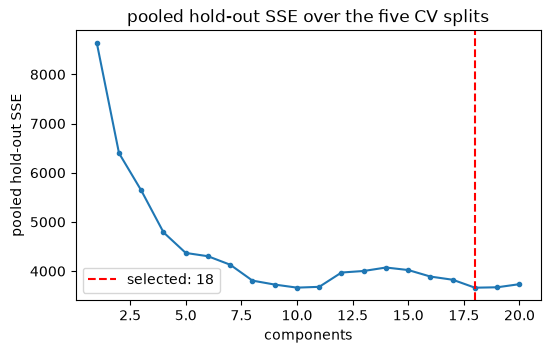

{'rmse': 5.721310138702393,
 'r2': 0.8109601140022278,
 'mae': 4.4907450675964355}

In [7]:
spectra_data = CourseNpzDataModule(
    universe_csv=str(DATA / "mean_spectra_03" / "universe.csv"),
    splits=load_splits(DATA / "mean_spectra_03" / "splits.json"),
    batch_size=32,
)
fit_trainer = StatisticalTrainer(pipeline=fit_pipeline, datamodule=spectra_data, metric_nodes=[metrics_pls])
fit_trainer.fit()
n_train = len(spectra_data.train_ds)
cv_rmse = float(torch.sqrt(pls.cv_sse[int(pls.n_selected) - 1] / n_train))
print(f"{int(pls.n_selected)} components selected on {n_train} training spectra, CV RMSE {cv_rmse:.3f}")
utils.plot_component_selection(pls.cv_sse, int(pls.n_selected), "pooled hold-out SSE over the five CV splits")
fit_test = fit_trainer.test()
pls_test_metrics = metrics_pls.compute()
pls_test_metrics

## 2. The U-Net ensemble on dequantised slices

The slices are stored as uint16 counts with a per-slice scale and bias; the study's dataset code
only dequantises them (`q / scale + bias`) before the network. The ensemble node runs the five
members one after another, which keeps one member's activations on the GPU at a time, and
averages their maps. The course ships the slice masks already on the U-Net's output grid, so they
go straight into the map statistics and the mask-weighted belly value with no resizing.

In [8]:
from cuvis_ai_wur_course.node.maps import ChemicalMapStatistics, Dequantize, GroupWeightedMean
from cuvis_ai_wur_course.node.unet import UNetChemicalMapEnsemble

slice_frame = CourseFrame(name="frame")
dequantize = Dequantize(name="dequantize")
unet = UNetChemicalMapEnsemble(name="unet", n_members=5, weights="hf")
unet_stats = ChemicalMapStatistics(name="stats", mask_scale=1)
belly_mean = GroupWeightedMean(name="belly_mean", max_groups=256)

unet_pipeline = CuvisPipeline("unet_ensemble_maps")
unet_pipeline.connect(
    (slice_frame.outputs.cube, dequantize.inputs.cube),
    (slice_frame.outputs.quant_scale, dequantize.inputs.quant_scale),
    (slice_frame.outputs.quant_bias, dequantize.inputs.quant_bias),
    (dequantize.outputs.cube, unet.inputs.cube),
    (unet.outputs.map, unet_stats.inputs.map),
    (slice_frame.outputs.mask, unet_stats.inputs.mask),
    (unet.outputs.map, belly_mean.inputs.map),
    (slice_frame.outputs.mask, belly_mean.inputs.mask),
    (slice_frame.outputs.group, belly_mean.inputs.group),
)
unet_pipeline

unet_ensemble_maps:
CourseFrame()
Dequantize()
UNetChemicalMapEnsemble(
  (members): ModuleList(
    (0-4): 5 x CompoundModel(
      (models): ModuleList(
        (0): Conv3Don2D(
          (conv): Conv3d(1, 1, kernel_size=(7, 2, 2), stride=(1, 2, 2), padding=valid)
          (norm_layer): Identity()
        )
        (1): UNet(
          (non_linearity): ReLU(inplace=True)
          (first_convs): Sequential(
            (0): Conv2d(56, 64, kernel_size=(3, 3), stride=(1, 1), padding=valid)
            (1): ReLU(inplace=True)
            (2): Identity()
            (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=valid)
            (4): ReLU(inplace=True)
            (5): Identity()
          )
          (last_conv): Conv2d(64, 1, kernel_size=(1, 1), stride=(1, 1))
          (contraction1): ContractionBlock(
            (max_pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
            (conv_block): Sequential(
              (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (1): ReLU(inplace=True)
              (2): Identity()
              (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (4): ReLU(inplace=True)
              (5): Identity()
            )
          )
          (contraction2): ContractionBlock(
            (max_pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
            (conv_block): Sequential(
              (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (1): ReLU(inplace=True)
              (2): Identity()
              (3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (4): ReLU(inplace=True)
              (5): Identity()
            )
          )
          (contraction3): ContractionBlock(
            (max_pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
            (conv_block): Sequential(
              (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (1): ReLU(inplace=True)
              (2): Identity()
              (3): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (4): ReLU(inplace=True)
              (5): Identity()
            )
          )
          (contraction4): ContractionBlock(
            (max_pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
            (conv_block): Sequential(
              (0): Conv2d(512, 1024, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (1): ReLU(inplace=True)
              (2): Identity()
              (3): Conv2d(1024, 1024, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (4): ReLU(inplace=True)
              (5): Identity()
            )
          )
          (expansion4): ExpansionBlock(
            (upsample): Upsample(
              (non_linearity): ReLU(inplace=True)
              (up): Sequential(
                (0): Upsample(scale_factor=2.0, mode='bilinear')
                (1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1))
                (2): ReLU(inplace=True)
                (3): Identity()
              )
            )
            (conv_block): Sequential(
              (0): Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (1): ReLU(inplace=True)
              (2): Identity()
              (3): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=valid)
              (4): ReLU(inplace=True)
              (5): Identity()
            )
          )
          (expansion3): ExpansionBlock(
            (upsample): Upsample(
              (non_linearity): ReLU(inplace=True)
              (up): Sequential(
                (0): Upsample(scale_factor=2.0, mode='bilinear')
                (1): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
                (2): ReLU(inplace=True)
                (3): Identity()
            

Predict [unet_ensemble_maps]:   0%|          | 0/10 [00:00<?, ?batch/s]

belly values (mask-weighted mean over every slice): {10: 29.85, 70: 62.25}


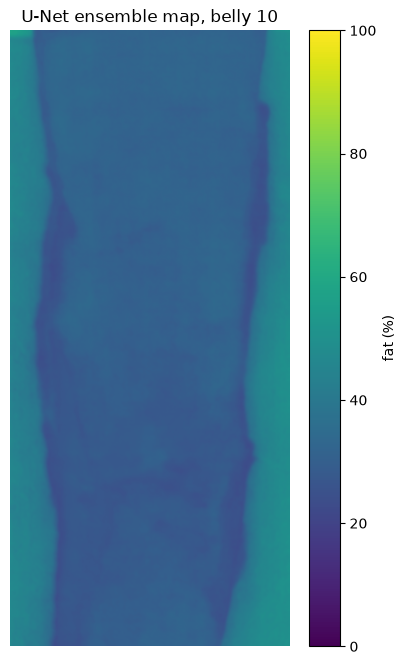

,belly,variance,nugget,1 - C0/var,out of range
0,10,3.6469,0.0069,0.9981,0.0
1,10,1.5672,0.0070,0.9955,0.0
2,10,1.8415,0.0071,0.9961,0.0
3,10,3.2624,0.0068,0.9979,0.0
4,10,3.3384,0.0068,0.9980,0.0
5,70,139.1200,0.0512,0.9996,0.0
6,70,80.3013,0.0388,0.9995,0.0
7,70,63.4036,0.0370,0.9994,0.0
8,70,45.3961,0.0336,0.9993,0.0
9,70,38.0125,0.0263,0.9993,0.0


In [9]:
from cuvis_ai_core.training import Predictor
from cuvis_ai_schemas.enums import ExecutionStage
from cuvis_ai_schemas.training.data import DataSplitConfig

slice_data = CourseNpzDataModule(
    universe_csv=str(DATA / "image_slices" / "universe.csv"),
    splits=DataSplitConfig(),  # an empty predict split means every slice
    batch_size=1,
)
unet_pipeline.to(DEVICE)
MAP_PORTS = {"map", "mask", "group", "variance", "nugget", "structured_share", "out_of_range_share"}
unet_out = Predictor(unet_pipeline, slice_data).predict(stage=ExecutionStage.INFERENCE, collect_outputs=True, collect_ports=MAP_PORTS)
belly_values = {int(group): round(float(value), 2) for group, value in belly_mean.compute().items()}
unet_table = pd.DataFrame(
    {
        "belly": [int(o[("frame", "group")][0]) for o in unet_out],
        "variance": [float(o[("stats", "variance")][0]) for o in unet_out],
        "nugget": [float(o[("stats", "nugget")][0]) for o in unet_out],
        "1 - C0/var": [float(o[("stats", "structured_share")][0]) for o in unet_out],
        "out of range": [float(o[("stats", "out_of_range_share")][0]) for o in unet_out],
    }
).round(4)
print("belly values (mask-weighted mean over every slice):", belly_values)
utils.show_map(unet_out[0][("unet", "map")][0], f"U-Net ensemble map, belly {unet_table.belly[0]}")
unet_table

## 3. The classical route pixel by pixel

The same PLS model, now on every pixel of a slice: dequantise, crop the centre region the U-Net
predicts (1992 x 904), convert to absorbance (`-log10`), SNV, Savitzky-Golay, PLS. The fitted
PLS state moves from the mean-spectra pipeline by node name, which is also how the trainrun's
saved weights would load into `pipelines/02_unet_chemical_maps/pls_pixel_map.yaml`. The map is at
full pixel resolution while the mask stays on the coarser U-Net output grid the course ships it
on, so the statistics node upsamples it by two, nearest neighbour, exactly as the course's
`np.kron(mask, np.ones((2, 2)))` does.

In [10]:
from cuvis_ai.node.pretreatments.logarithm import Logarithm
from cuvis_ai_wur_course.node.maps import CenterCrop

pixel_frame = CourseFrame(name="frame")
pixel_dequantize = Dequantize(name="dequantize")
crop = CenterCrop(name="crop", crop_height=1992, crop_width=904)
absorbance = Logarithm(name="absorbance", mode="log10", negate=True, eps=1e-6)
pixel_snv = Standardize(name="snv", axis="spectrum", ddof=0)
pixel_sg = SavitzkyGolayInterp(name="sg", num_channels=BINNED, window_length=7, polyorder=2, deriv=2)
pixel_pls = PLSRegression(name="pls", input_channels=BINNED, max_components=MAX_COMPONENTS, holdout_folds="each", refit_on_holdout=True)
pixel_stats = ChemicalMapStatistics(name="stats", mask_scale=2)

pixel_pipeline = CuvisPipeline("pls_pixel_map")
pixel_pipeline.connect(
    (pixel_frame.outputs.cube, pixel_dequantize.inputs.cube),
    (pixel_frame.outputs.quant_scale, pixel_dequantize.inputs.quant_scale),
    (pixel_frame.outputs.quant_bias, pixel_dequantize.inputs.quant_bias),
    (pixel_dequantize.outputs.cube, crop.inputs.cube),
    (crop.outputs.cube, absorbance.inputs.cube),
    (absorbance.outputs.cube, pixel_snv.inputs.cube),
    (pixel_snv.outputs.cube, pixel_sg.inputs.cube),
    (pixel_sg.outputs.cube, pixel_pls.inputs.cube),
    (pixel_pls.outputs.prediction, pixel_stats.inputs.map),
    (pixel_frame.outputs.mask, pixel_stats.inputs.mask),
)
# the fitted state moves by node name
pixel_pls.load_state_dict(pls.state_dict())
pixel_pipeline

pls_pixel_map:
CourseFrame()
Dequantize()
CenterCrop()
Logarithm()
Standardize()
SavitzkyGolayInterp()
PLSRegression()
ChemicalMapStatistics()
Use `pipeline.visualize()` for Graphviz/Mermaid output.

Predict [pls_pixel_map]:   0%|          | 0/10 [00:00<?, ?batch/s]

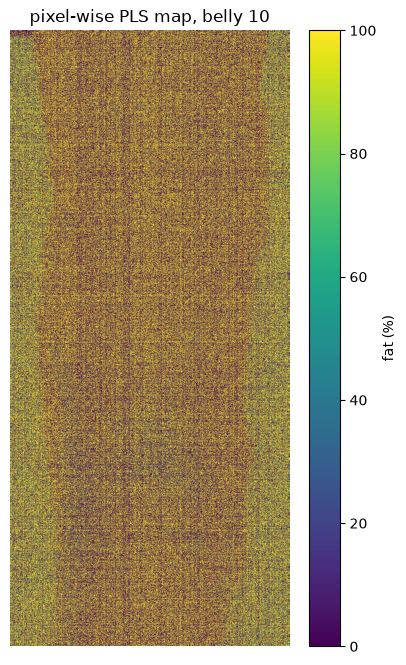

,belly,variance,nugget,1 - C0/var,out of range
0,10,114981.2266,112551.0000,0.0211,0.8776
1,10,117651.2578,114971.8281,0.0228,0.8820
2,10,117796.5859,114943.0781,0.0242,0.8815
3,10,114768.1016,111988.2812,0.0242,0.8800
4,10,98697.7031,96588.3672,0.0214,0.8670
5,70,139901.6250,136699.8594,0.0229,0.8891
6,70,101175.1094,98608.7031,0.0254,0.8693
7,70,111517.6875,108485.3906,0.0272,0.8763
8,70,123481.7891,120237.8438,0.0263,0.8823
9,70,133517.5312,130160.0938,0.0251,0.8873


In [11]:
pixel_pipeline.to(DEVICE)
pixel_out = Predictor(pixel_pipeline, slice_data).predict(stage=ExecutionStage.INFERENCE, collect_outputs=True, collect_ports={"prediction", "group", "variance", "nugget", "structured_share", "out_of_range_share"})
pixel_table = pd.DataFrame(
    {
        "belly": [int(o[("frame", "group")][0]) for o in pixel_out],
        "variance": [float(o[("stats", "variance")][0]) for o in pixel_out],
        "nugget": [float(o[("stats", "nugget")][0]) for o in pixel_out],
        "1 - C0/var": [float(o[("stats", "structured_share")][0]) for o in pixel_out],
        "out of range": [float(o[("stats", "out_of_range_share")][0]) for o in pixel_out],
    }
).round(4)
utils.show_map(pixel_out[0][("pls", "prediction")][0], f"pixel-wise PLS map, belly {pixel_table.belly[0]}")
pixel_table

## Reproduction

The course numbers are the printed outputs of the course notebook at the commit named at the top:
the U-Net belly values of bellies 10 and 70, the share of U-Net map pixels outside 0 to 100
percent, the mean structured share of the U-Net maps, the PLS component count and CV RMSE, and
the two map statistics of the PLS map. The course computes the PLS map for the first test slice
only (belly 10, slice 1), so those two rows take the first row of the table above; the other
nine slices are extra. The U-Net demo training run with the study's losses is deferred.

In [12]:
rows = [
    ("U-Net belly 10 (%)", 29.85, belly_values.get(10, "belly 10 absent"), 1e-2),
    ("U-Net belly 70 (%)", 62.25, belly_values.get(70, "belly 70 absent"), 1e-2),
    ("U-Net map, share outside 0 to 100 (%)", 0.0, round(100 * unet_table["out of range"].mean(), 3), 1e-2),
    ("U-Net map, mean 1 - C0/var", 0.9983, round(float(unet_table["1 - C0/var"].mean()), 4), 1e-2),
    ("PLS components", 18, int(pls.n_selected), 0),
    ("PLS CV RMSE", 5.48, round(cv_rmse, 3), 1e-2),
    ("PLS map of the first slice, share outside 0 to 100 (%)", 87.76, round(100 * float(pixel_table["out of range"][0]), 3), 1e-2),
    ("PLS map of the first slice, 1 - C0/var", 0.0211, round(float(pixel_table["1 - C0/var"][0]), 4), 1e-2),
]
utils.reproduction_table(rows, synthetic=SYNTHETIC)

,row,course,ours,tolerance,status
0,U-Net belly 10 (%),29.8500,29.8500,0.01,pass
1,U-Net belly 70 (%),62.2500,62.2500,0.01,pass
2,"U-Net map, share outside 0 to 100 (%)",0.0000,0.0000,0.01,pass
3,"U-Net map, mean 1 - C0/var",0.9983,0.9983,0.01,pass
4,PLS components,18.0000,18.0000,0.00,pass
5,PLS CV RMSE,5.4800,5.4790,0.01,pass
6,"PLS map of the first slice, share outside 0 to...",87.7600,87.7600,0.01,pass
7,"PLS map of the first slice, 1 - C0/var",0.0211,0.0211,0.01,pass
